<a href="https://colab.research.google.com/github/Mitochondrion3000/epic-competiton/blob/claude/gracious-brown-4ybsmj/simple_model/step4_test_and_submission.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Простая интерпретируемая модель. Шаг 4: тест, официальные метрики и сабмит

Берём финальные модели шага 3б и предсказываем **все позиции тестового шаблона** (у *Nematostella* это 72.6 млн
позиций-цепей на трёх хромосомах), в том порядке, который ждёт скорер. Для учебного вида есть ответы теста, поэтому
считаем официальные метрики (на двух половинах теста, как на лидерборде) и сравниваем с CNN.
В конце пишем файл сабмита и смотрим на пару участков генома глазами.

Для своего вида (`Ofas_2.0`) последовательность та же: шаги 1 → 2 → 3 → 3б → 4 с `EPIC_SPECIES=Ofas_2.0`;
ответов теста там нет, и раздел с оценкой просто пропустится.

## 0. Настройки, модели, шаблон теста

In [1]:
import os, sys, gzip, json, hashlib, tarfile, time, urllib.request
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
try:
    import lightgbm as lgb
except ImportError:
    os.system("pip install -q lightgbm"); import lightgbm as lgb

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

SPECIES = os.environ.get("EPIC_SPECIES", "jaNemVect1.1")
ON_COLAB = "google.colab" in sys.modules
if ON_COLAB:
    from google.colab import drive; drive.mount("/content/drive")
DATA_DIR = os.environ.get("EPIC_DATA_DIR", "/content/epic")
OUT_DIR = os.environ.get("EPIC_OUT_DIR", "/content/drive/MyDrive/epic_simple" if ON_COLAB else "/content/epic_simple")
BASE, FP = f"{DATA_DIR}/{SPECIES}", f"{DATA_DIR}/{SPECIES}/for_participants"

RAW = "https://raw.githubusercontent.com/Mitochondrion3000/epic-competiton/claude/gracious-brown-4ybsmj/simple_model/"
for mod in ("features.py", "motifs.py", "scoring.py"):
    if not os.path.exists(mod): urllib.request.urlretrieve(RAW + mod, mod)
import features as F, motifs as M, scoring as S

P = json.load(open(f"{OUT_DIR}/{SPECIES}.step3b_params.json"))
FEATURES = P["features"]
PARAMS = {"pwm": np.array(P["pwm"]), "kmers": [tuple(k) for k in P["kmers"]], "tf": P["tf"], "wide": P["wide"], "local": P["local"]}
SUMMARY = json.load(open(f"{OUT_DIR}/{SPECIES}.step3b_summary.json"))
ALPHA = SUMMARY["alpha"]
MODELS = {tag: (lgb.Booster(model_file=f"{OUT_DIR}/{SPECIES}.step3b_{tag}_cls.txt"),
                lgb.Booster(model_file=f"{OUT_DIR}/{SPECIES}.step3b_{tag}_reg.txt")) for tag in ("additive", "depth3")}
print(f"{len(FEATURES)} признаков, модели: {list(MODELS)}, alpha = {ALPHA}")

61 признаков, модели: ['additive', 'depth3'], alpha = 0.4


In [2]:
def download_dataset(species, data_dir):
    if os.path.isdir(f"{data_dir}/{species}"): return
    import requests
    os.makedirs(data_dir, exist_ok=True)
    rec = requests.get("https://zenodo.org/api/records/22285753", timeout=60).json()
    f = [x for x in rec["files"] if x["key"] == f"{species}.tgz"][0]
    dst, md5 = f"{data_dir}/{species}.tgz", hashlib.md5()
    with requests.get(f["links"]["self"], stream=True, timeout=120) as r, open(dst, "wb") as fh:
        r.raise_for_status()
        for chunk in tqdm(r.iter_content(1 << 22), total=f["size"] // (1 << 22) + 1, desc=f"скачиваю {species}"):
            fh.write(chunk); md5.update(chunk)
    assert md5.hexdigest() == f.get("checksum", "md5:").split(":")[-1], "MD5 не совпал"
    with tarfile.open(dst) as tf:
        try: tf.extractall(data_dir, filter="data")
        except TypeError: tf.extractall(data_dir)
    os.remove(dst)

CODE = np.full(256, 4, np.uint8)
for i, b in enumerate("ACGT"):
    CODE[ord(b)] = CODE[ord(b.lower())] = i

def read_genome(path, keep):
    seq, low, name, chunks = {}, {}, None, []
    def flush():
        if name in keep:
            raw = np.frombuffer(b"".join(chunks), np.uint8)
            seq[name], low[name] = CODE[raw], raw >= ord("a")
    with gzip.open(path, "rb") as fh:
        for line in fh:
            if line.startswith(b">"):
                flush(); name, chunks = line[1:].split()[0].decode(), []
            elif name in keep:
                chunks.append(line.rstrip())
    flush()
    return seq, low

download_dataset(SPECIES, DATA_DIR)
tpl = pd.read_csv(f"{FP}/template.test.bed.gz", sep="\t", header=None, usecols=[0, 1, 2, 5],
                  names=["chrom", "start", "end", "strand"], dtype={"chrom": str, "strand": str})
tpl["len"] = tpl.end - tpl.start
tpl["off"] = np.r_[0, np.cumsum(tpl.len.values)[:-1]]       # где в итоговом векторе начинается каждая строка шаблона
N_TOTAL = int(tpl.len.sum())
SEQ, LOW = read_genome(f"{BASE}/genome/genome.fa.gz", set(tpl.chrom))
print(f"шаблон: {len(tpl):,} строк, {N_TOTAL:,} позиций-цепей, контиги: {list(dict.fromkeys(tpl.chrom))}")
print("порядок цепей в шаблоне:", tpl.strand.iloc[[0, len(tpl) // 2 - 1, len(tpl) // 2, -1]].tolist(), "(сначала все '+', потом все '−')")

шаблон: 54,846 строк, 72,613,390 позиций-цепей, контиги: ['NC_064037.1', 'NC_064044.1', 'NC_064046.1']
порядок цепей в шаблоне: ['+', '+', '-', '-'] (сначала все '+', потом все '−')


## 1. Предсказание всех позиций теста

Для каждого контига и каждой цепи собираем позиции всех строк шаблона, считаем 61 признак той же функцией, что на
обучении (`features.feature_matrix`), прогоняем обе модели и раскладываем счёт в порядок шаблона.
Счёт модели = `log P(старт) + E[log(1 + счёт) | старт]`. Позиции с `N` в геноме получают самый низкий счёт.
Занимает около 15–20 минут, пик памяти ~4 ГБ.

In [3]:
SCORES = {tag: np.zeros(N_TOTAL, np.float32) for tag in MODELS}
NMASK = np.zeros(N_TOTAL, bool)
t0 = time.time()
for (c, st), g in tqdm(tpl.groupby(["chrom", "strand"], sort=False), desc="контиг × цепь"):
    pos = np.concatenate([np.arange(s, e) for s, e in zip(g.start.values, g.end.values)])
    dst = np.concatenate([np.arange(o, o + n) for o, n in zip(g.off.values, g.len.values)])
    X = F.feature_matrix(SEQ[c], LOW[c], pos, np.full(len(pos), st), PARAMS, FEATURES)
    for tag, (clf, reg) in MODELS.items():
        SCORES[tag][dst] = np.log(np.clip(clf.predict(X), 1e-12, 1)) + reg.predict(X)
    NMASK[dst] = SEQ[c][pos] == 4
    del X
    print(f"{c} {st}: {len(pos):,} позиций, {(time.time() - t0) / 60:.1f} мин", flush=True)
for tag, s in SCORES.items():
    s[NMASK] = -np.inf
    np.save(f"{OUT_DIR}/{SPECIES}.step4_{tag}_score.npy", s)
print(f"готово: {N_TOTAL:,} позиций, N-позиций {NMASK.sum():,}")

NC_064037.1 +: 13,880,887 позиций, 4.1 мин


NC_064044.1 +: 10,989,536 позиций, 7.0 мин


NC_064046.1 +: 11,436,272 позиций, 10.3 мин


NC_064037.1 -: 13,880,887 позиций, 14.5 мин


NC_064044.1 -: 10,989,536 позиций, 17.6 мин


NC_064046.1 -: 11,436,272 позиций, 20.7 мин


готово: 72,613,390 позиций, N-позиций 9,600


## 2. Официальные метрики на тесте

Скорер оценивает каждую половину теста отдельно (`mask1` и `mask2`, это половины, как на публичном и приватном
лидерборде), итог — среднее по половинам. Перед оценкой счёт квантуется так же, как будет записан в файл
(`rank_power` с `alpha` из шага 3б).

,AUPRC,Spearman,AUPRC half1,AUPRC half2,Spearman half1,Spearman half2
случайный уровень,0.0007,0.0000,—,—,—,—
динуклеотиды (бейзлайн организаторов),0.0012,0.0361,—,—,—,—
PWM старта (EDA)*,0.0019,0.1530,—,—,—,—
dilated CNN (наш прошлый пайплайн)*,0.0434,0.3790,—,—,—,—
InitiationNet big 96k (лучшая CNN),0.1316,0.3910,—,—,—,—
НАША: аддитивная модель,0.0170,0.1598,0.0187,0.0152,0.1699,0.1497
НАША: деревья глубины 3,0.0201,0.1955,0.0249,0.0154,0.1950,0.1961


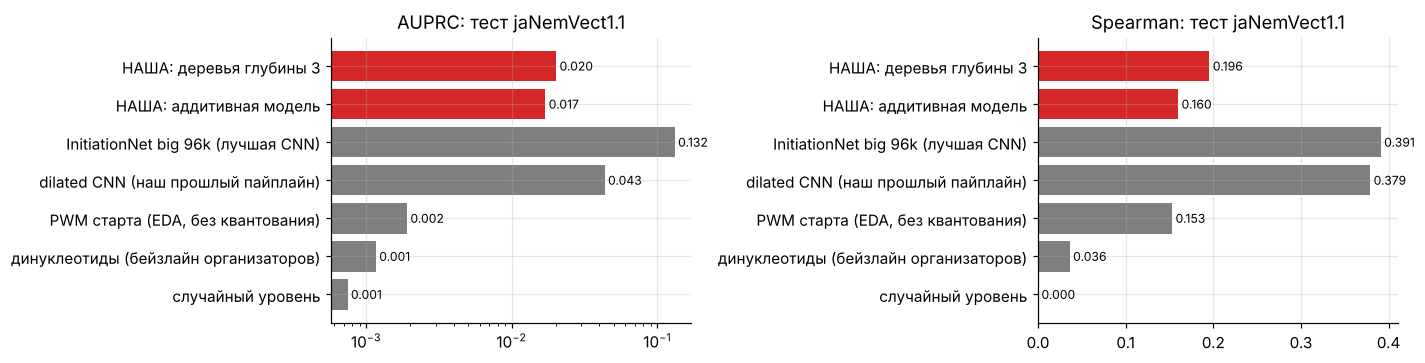

In [4]:
HAS_GT = os.path.exists(f"{BASE}/ground_truth/csRNA-test.txt.gz")
if HAS_GT:
    read_col = lambda p, dt: pd.read_csv(p, header=None, dtype=dt)[0].values
    GT = read_col(f"{BASE}/ground_truth/csRNA-test.txt.gz", np.float32)
    M1 = read_col(f"{BASE}/scoring/mask1-test.txt.gz", np.int8).astype(bool); M2 = read_col(f"{BASE}/scoring/mask2-test.txt.gz", np.int8).astype(bool)
    assert len(GT) == N_TOTAL
    rows = {}
    for tag, name in (("additive", "аддитивная модель"), ("depth3", "деревья глубины 3")):
        sub = S.rank_power(SCORES[tag], ALPHA, NMASK)
        r = {h: S.official_score(sub, GT, m) for h, m in (("half1", M1), ("half2", M2))}
        rows[f"НАША: {name}"] = {"AUPRC": np.mean([r[h]["AUPRC"] for h in r]), "Spearman": np.mean([r[h]["Spearman"] for h in r]),
                                 "AUPRC half1": r["half1"]["AUPRC"], "AUPRC half2": r["half2"]["AUPRC"],
                                 "Spearman half1": r["half1"]["Spearman"], "Spearman half2": r["half2"]["Spearman"]}
    REF = {"случайный уровень": (float((GT > 0).mean()), 0.0), "динуклеотиды (бейзлайн организаторов)": (0.00116, 0.0361),
           "PWM старта (EDA)*": (0.0019, 0.153), "dilated CNN (наш прошлый пайплайн)*": (0.0434, 0.379),
           "InitiationNet big 96k (лучшая CNN)": (0.13165, 0.391)}
    cmp = pd.concat([pd.DataFrame({k: {"AUPRC": a, "Spearman": s} for k, (a, s) in REF.items()}).T, pd.DataFrame(rows).T])
    display(cmp.style.format("{:.4f}", na_rep="—"))
    fig, ax = plt.subplots(1, 2, figsize=(13, 3.4))
    for a, met in zip(ax, ("AUPRC", "Spearman")):
        v = cmp[met]; cols = ["tab:red" if i.startswith("НАША") else "tab:gray" for i in cmp.index]
        a.barh(cmp.index, v, color=cols); a.set_title(f"{met}: тест {SPECIES}")
        for i, x in enumerate(v): a.text(x, i, f" {x:.3f}", va="center", fontsize=8)
        if met == "AUPRC": a.set_xscale("log")
    plt.tight_layout(); plt.show()
else:
    print("ответов теста нет (это не учебный вид) — оценку пропускаем")

**Итог на официальном тесте *Nematostella* (среднее по двум половинам):**

| модель | AUPRC | Spearman |
|---|---|---|
| случайный уровень | 0.0007 | 0 |
| динуклеотиды (бейзлайн организаторов) | 0.0012 | 0.036 |
| **наша аддитивная модель** (61 понятный признак, без взаимодействий) | **0.017** | **0.160** |
| **наши деревья глубины 3** | **0.020** | **0.196** |
| InitiationNet big (лучшая CNN) | 0.132 | 0.391 |

(Строки «PWM старта» и «наш прошлый dilated CNN» посчитаны в своё время без квантования сабмита и обычным Spearman,
поэтому сравнивать с ними можно только примерно.)

* Простая модель **в 17 раз лучше бейзлайна организаторов по AUPRC и в 5 раз по Spearman**, и каждый её шаг объясним.
* До CNN она не дотягивает: AUPRC в **6.5 раза** ниже, Spearman в **2 раза** ниже.
* Оценка на плотной валидации (0.0245) хорошо предсказала тест (0.020): разница в основном из-за half2, где AUPRC
  у нас 0.015 против 0.025 на half1. Половины теста заметно отличаются, CNN тоже даёт на них разные числа.

## 3. Как это выглядит на геноме

Три самых сильных старта теста, ±150 нт: сверху настоящие старты (счёт csRNA-seq на каждой цепи), ниже
счёт модели (место позиции в рейтинге всего теста), ещё ниже — сайты факторов и состав, из которых модель этот счёт собрала. Так видно, *почему* модель
поставила высокий счёт в одном месте и низкий в соседнем.

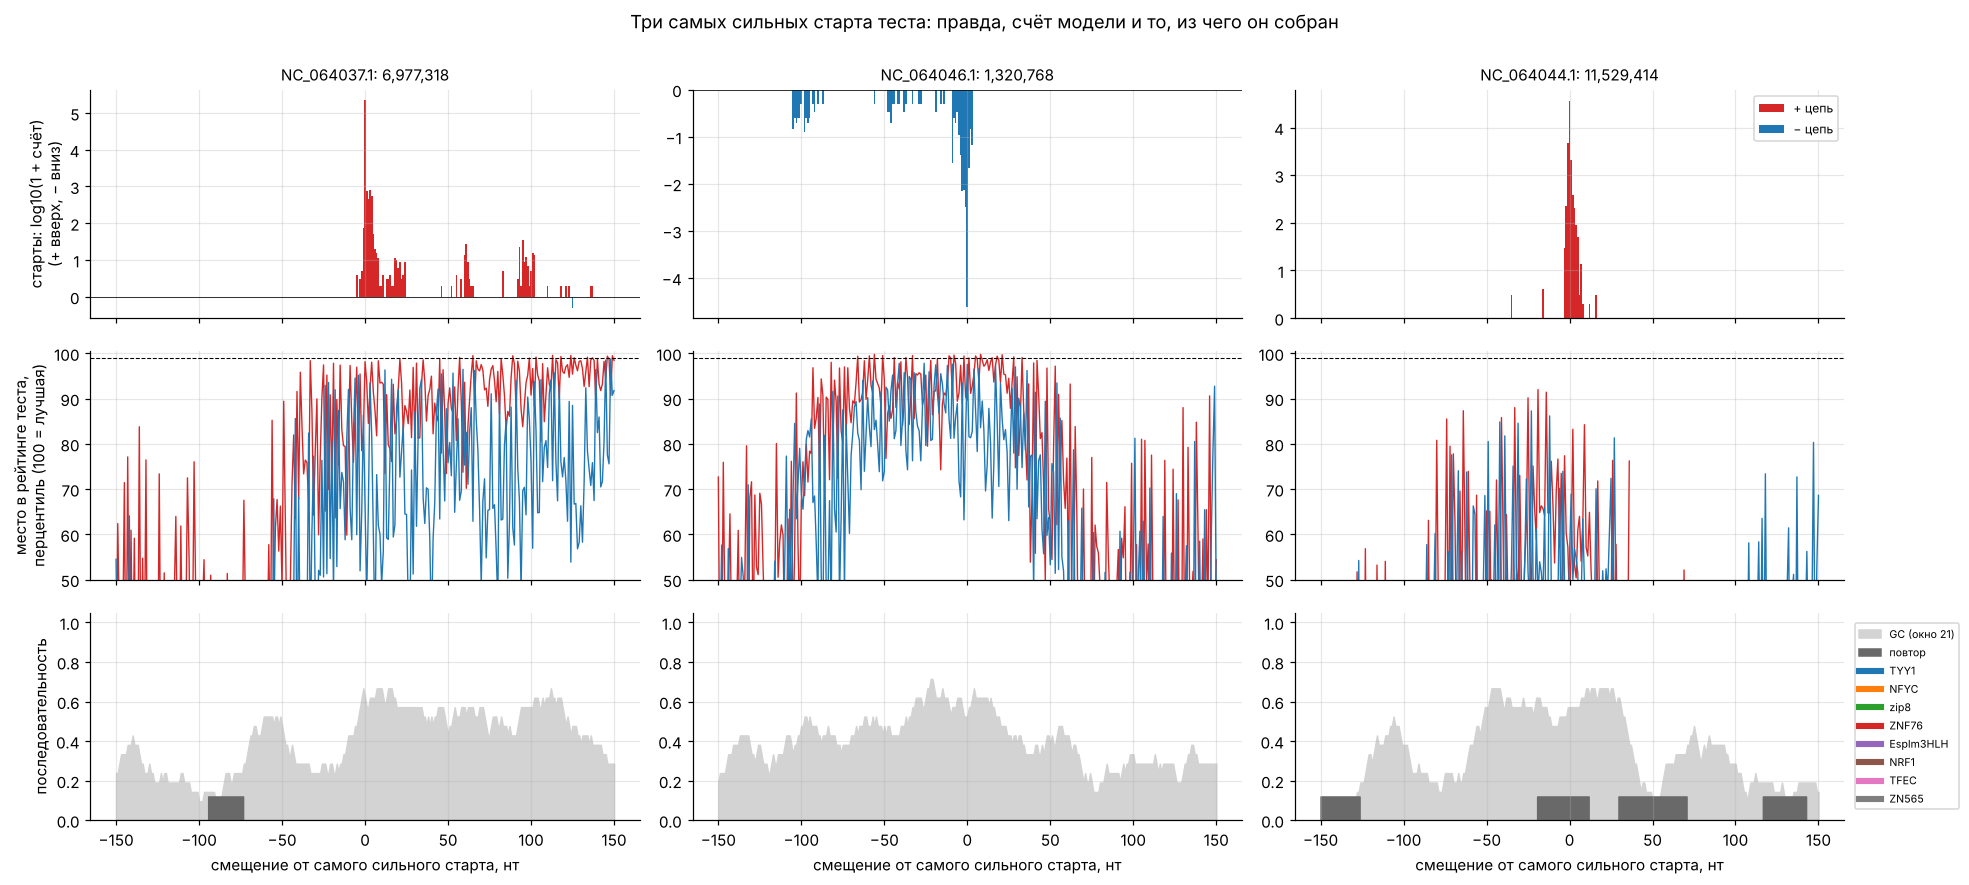

In [5]:
if HAS_GT:
    tag = "depth3"
    # самые сильные старты теста (не ближе 50 т.н. друг к другу) -> окно ±150 нт вокруг каждого
    picked, used = [], []
    for k in np.argsort(-GT)[:2000]:
        r = np.searchsorted(tpl.off.values, k, side="right") - 1
        c, pos = tpl.chrom.iat[r], tpl.start.iat[r] + (k - tpl.off.iat[r])
        if all(c != u[0] or abs(pos - u[1]) > 50_000 for u in used):
            used.append((c, pos)); picked.append((c, pos))
        if len(picked) == 3: break
    # счёт модели переводим в «место в рейтинге всего теста»: 100 = лучшая позиция, 0 = худшая
    finite = np.isfinite(SCORES[tag])
    PCT = np.zeros(N_TOTAL, np.float32)
    PCT[finite] = 100 * (np.argsort(np.argsort(SCORES[tag][finite])) / finite.sum())

    def track(c, lo, hi, vec):
        out = np.full((2, hi - lo), np.nan, np.float32)
        g = tpl[(tpl.chrom == c) & (tpl.end > lo) & (tpl.start < hi)]
        for s, e, st, o in zip(g.start.values, g.end.values, g.strand.values, g.off.values):
            a, b = max(s, lo), min(e, hi)
            out[0 if st == "+" else 1, a - lo:b - lo] = vec[o + a - s:o + b - s]
        return out

    H = 150
    fig, axs = plt.subplots(3, len(picked), figsize=(6 * len(picked), 8), sharex=True,
                            gridspec_kw={"height_ratios": [1.1, 1.1, 1.0]})
    for n, (c, center) in enumerate(picked):
        lo, hi = center - H, center + H + 1; x = np.arange(lo, hi) - center
        gt, pc = track(c, lo, hi, GT), track(c, lo, hi, PCT)
        a0, a1, a2 = axs[0, n], axs[1, n], axs[2, n]
        a0.bar(x, np.log10(1 + np.nan_to_num(gt[0])), color="tab:red", width=1, label="+ цепь")
        a0.bar(x, -np.log10(1 + np.nan_to_num(gt[1])), color="tab:blue", width=1, label="− цепь")
        a0.axhline(0, color="k", lw=.5); a0.set_title(f"{c}: {center:,}", fontsize=10)
        a1.plot(x, pc[0], color="tab:red", lw=.9); a1.plot(x, pc[1], color="tab:blue", lw=.9)
        a1.axhline(99, color="k", ls="--", lw=.7); a1.set_ylim(50, 100.5)
        s = SEQ[c][lo:hi]; gcw = np.convolve(((s == 1) | (s == 2)).astype(float), np.ones(21) / 21, mode="same")
        a2.fill_between(x, 0, gcw, color="lightgray", label="GC (окно 21)")
        a2.fill_between(x, 0, LOW[c][lo:hi] * 0.12, color="dimgray", step="mid", label="повтор")
        for k, m in enumerate(P["tf"][:8]):
            # сайт фактора двуцепочечный (счёт берёт максимум по двум ориентациям), поэтому ищем по + цепи
            h = np.flatnonzero(M.score_track(s, np.array(m["pwm"], np.float32)) >= m["thr"])
            w = len(m["pwm"])
            for hh in h:
                a2.plot([x[hh], x[min(hh + w - 1, len(x) - 1)]], [0.62 + 0.05 * k] * 2, color=plt.cm.tab10(k), lw=4, solid_capstyle="butt")
            a2.plot([], [], color=plt.cm.tab10(k), lw=4, label=m["name"])
        a2.set_ylim(0, 1.05); a2.set_xlabel("смещение от самого сильного старта, нт")
    axs[0, 0].set_ylabel("старты: log10(1 + счёт)\n(+ вверх, − вниз)"); axs[1, 0].set_ylabel("место в рейтинге теста,\nперцентиль (100 = лучшая)")
    axs[2, 0].set_ylabel("последовательность")
    axs[0, -1].legend(fontsize=8, loc="upper right")
    axs[2, -1].legend(fontsize=7, loc="center left", bbox_to_anchor=(1.01, 0.5))
    plt.suptitle("Три самых сильных старта теста: правда, счёт модели и то, из чего он собран", y=1.0)
    plt.tight_layout(); plt.show()

**Что видно на трёх самых сильных стартах теста:**
* **Область промотора модель находит:** в ±50 нт от старта счёт модели попадает в верхние 5–10% всех позиций теста,
  а за пределами промотора падает ниже медианы. Это работа GC-контраста, повторов и сайтов факторов.
* **Точную позицию — нет:** соседние буквы получают очень разные счета (кривая скачет между 60-м и 99-м перцентилем),
  потому что мотив Initiator зависит от каждой отдельной буквы, а настоящие старты лежат «пучком» на десятке соседних
  позиций. Это главная причина отставания от CNN по AUPRC: CNN сглаживает и уточняет предсказание по рисунку
  в сотни нуклеотидов вокруг.
* **Третий старт** (NC_064044.1) лежит рядом с повторами (тёмные полосы), и модель ставит его только около 80-го
  перцентиля: признак «повторы рядом» тянет вниз, хотя здесь это настоящий сильный старт.
* В этих трёх промоторах нет сайтов отобранных факторов: самые сильные старты, вероятно, принадлежат особым генам
  (малые РНК, рибосомные белки), у которых свои мотивы.

## 4. Файл сабмита

Лучшая модель (деревья глубины 3), квантование `rank_power(alpha)`, 5 знаков после запятой, одна строка на позицию
в порядке шаблона, `N` → 0. Перед загрузкой файл стоит проверить официальным валидатором:
https://github.com/autosome-ru/EPIC_scoring

In [6]:
SUB = S.rank_power(SCORES["depth3"], ALPHA, NMASK)
sub_path = f"{OUT_DIR}/{SPECIES}.simple_model.predictions.txt.gz"
S.write_submission(SUB, sub_path)
with gzip.open(sub_path, "rt") as fh:
    head = [next(fh).strip() for _ in range(3)]
checks = {"строк = позиций шаблона": len(SUB) == N_TOTAL, "все значения в [0, 1]": bool((SUB >= 0).all() and (SUB <= 1).all()),
          "N-позиции = 0": bool((SUB[NMASK] == 0).all()), "первые строки": head,
          "различных значений": int(len(np.unique(S.quantise(SUB)))), "alpha": ALPHA,
          "размер файла, МБ": round(os.path.getsize(sub_path) / 1e6, 1)}
display(pd.Series(checks, name="проверка").to_frame())
assert checks["строк = позиций шаблона"] and checks["все значения в [0, 1]"]
if HAS_GT:
    print("контроль: метрики по записанному вектору", {h: {k: round(v, 4) for k, v in S.official_score(SUB, GT, m).items()} for h, m in (("half1", M1), ("half2", M2))})
print("сабмит:", sub_path)

,проверка
строк = позиций шаблона,True
"все значения в [0, 1]",True
N-позиции = 0,True
первые строки,"[0.00095, 0.00094, 0.00091]"
различных значений,6709
alpha,0.4
"размер файла, МБ",106.9


контроль: метрики по записанному вектору {'half1': {'AUPRC': 0.0249, 'Spearman': 0.195}, 'half2': {'AUPRC': 0.0154, 'Spearman': 0.1961}}
сабмит: /content/drive/MyDrive/epic_simple/jaNemVect1.1.simple_model.predictions.txt.gz


## Итог серии

**Что получилось за четыре шага.** Модель целиком собрана из понятных частей:

1. **Сам старт:** мотив Initiator `C[A]` (PWM на −5..+5).
2. **Промотор:** GC-богатый островок в AT-богатом окружении без повторов; CpG; поли-A/T обеднены у старта.
3. **Факторы транскрипции из JASPAR/HOCOMOCO в своих окнах:** YY1 на старте, NF-Y на −110..−40, CREB/ATF, NRF1,
   ZNF76, HINFP, E-бокс.
4. **Структура гена:** донор сплайсинга вскоре после старта.

Модель — неглубокие деревья (или, ещё проще, аддитивная модель с одной кривой на признак). Тест *Nematostella*:
**AUPRC 0.020, Spearman 0.196** (аддитивная: 0.017 / 0.160); бейзлайн организаторов 0.0012 / 0.036, лучшая CNN 0.132 / 0.391.

**Почему отстаём от CNN и что можно сделать дальше:**
* точная позиция внутри «пучка» стартов: сгладить счёт по соседям (например, взять максимум или среднее Inr по ±5 нт);
* сила старта (Spearman): у нас нет признаков, отличающих очень сильные промоторы (например, гены рибосомных белков,
  малых РНК); можно поискать мотивы именно у сильных стартов (`TCT`, PSE/SNAPc);
* мотивы, которых нет в базах (книдарии далеки от человека и мухи): поиск мотивов de novo по стартам (STREME/HOMER).

**Для своего вида (`Ofas_2.0`):** запустить шаги 1 → 2 → 3 → 3б → 4 с `EPIC_SPECIES=Ofas_2.0`. Шаги 2–3 сами
выберут мотивы и факторы по данным этого вида; оценка на тесте пропустится (ответов нет), сабмит запишется.